## A — Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from transformers import AutoImageProcessor, AutoModel

from src.data import PoseDataset, CROWDPOSE_JOINT_NAMES

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_NAME = "facebook/dinov3-convnext-small-pretrain-lvd1689m"
IMAGE_SIZE = 224  # matches scripts/precompute_dino.py default

ANN_PATH = "data/crowdpose/annotations/crowdpose_val.json"
IMG_ROOT = "data/crowdpose/images"

STAGE_STRIDES = {"stage1": 4, "stage2": 8, "stage3": 16, "stage4": 32}
STAGE_NAMES = list(STAGE_STRIDES.keys()) + ["global"]

print("device:", DEVICE)

device: cuda


In [3]:
# Load CrowdPose val
dataset = PoseDataset.from_path(ANN_PATH, IMG_ROOT)
print(f"PoseDataset: {len(dataset)} images")

ex = dataset[0]
print("keys:", list(ex.keys()))
print("keypoints:", ex["keypoints"].shape, " visibility:", ex["visibility"].shape)
print("img_path:", ex["img_path"])

PoseDataset: 2000 images
keys: ['image_id', 'img_path', 'keypoints', 'visibility']
keypoints: torch.Size([3, 14, 2])  visibility: torch.Size([3, 14])
img_path: data/crowdpose/images/114203.jpg


In [4]:
# Load DINOv3 ConvNeXt-Small backbone
processor = AutoImageProcessor.from_pretrained(
    MODEL_NAME,
    use_fast=True,
    do_center_crop=False,
    size={"shortest_edge": IMAGE_SIZE},
)
backbone = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE).eval()
for p in backbone.parameters():
    p.requires_grad_(False)
print("backbone class:", type(backbone).__name__)

Loading weights:   0%|          | 0/342 [00:00<?, ?it/s]

backbone class: DINOv3ConvNextModel


## B — Feature extraction utility

For one image we want, per stage, a feature map of shape `(C, Hs, Ws)` plus
the pooled `global` vector. We then sample features at GT joint pixel
locations using bilinear `grid_sample` with normalized coordinates so that
non-square images are handled correctly.

For each sampled joint we also keep:
- the patch-center pixel coordinates (in the resized image) of the nearest
  patch, used to compute the regression target `(Δx, Δy)` in original-image
  pixels.

Note: the processor resizes the image (shortest edge → IMAGE_SIZE) and may
round so that H,W are divisible by 32. We rely on the actual feature-map
shape returned by the model rather than computing it ourselves.

In [5]:
@torch.no_grad()
def extract_stage_features(pil_img: Image.Image) -> dict:
    """Run DINOv3 ConvNeXt on one PIL image and return all stage features.

    Returns dict with:
      stage1..stage4: Tensor(C, Hs, Ws)  on DEVICE
      global:         Tensor(C,)         on DEVICE
      resized_hw:     (H_resized, W_resized) of the processor output
      orig_hw:        (H_orig, W_orig) of the input PIL image
    """
    orig_hw = (pil_img.height, pil_img.width)
    inputs = processor(images=pil_img, return_tensors="pt").to(DEVICE)
    pixel_values = inputs["pixel_values"]  # (1, 3, H, W)
    resized_hw = (pixel_values.shape[-2], pixel_values.shape[-1])

    outputs = backbone(**inputs, output_hidden_states=True)
    # hidden_states: 0=input, 1..4 = stage1..stage4
    feats = {
        f"stage{i}": outputs.hidden_states[i][0]  # (C, Hs, Ws)
        for i in (1, 2, 3, 4)
    }
    feats["global"] = outputs.pooler_output[0]    # (C,)
    feats["resized_hw"] = resized_hw
    feats["orig_hw"] = orig_hw
    return feats

In [6]:
def sample_at_joints(
    feat_map: torch.Tensor,         # (C, Hs, Ws)
    kpt_xy_orig: torch.Tensor,      # (M, 2) pixel coords in ORIGINAL image
    orig_hw: tuple[int, int],
    resized_hw: tuple[int, int],
) -> tuple[torch.Tensor, torch.Tensor]:
    """Bilinearly sample feat_map at given pixel locations.

    Returns:
      feats    : Tensor(M, C)            sampled feature vectors
      patch_xy : Tensor(M, 2)            nearest-patch center, in ORIGINAL image px
    """
    Ho, Wo = orig_hw
    Hr, Wr = resized_hw
    C, Hs, Ws = feat_map.shape

    # original-px -> resized-px -> normalized [-1, 1] for grid_sample
    kx = kpt_xy_orig[:, 0] * (Wr / Wo)
    ky = kpt_xy_orig[:, 1] * (Hr / Ho)
    # grid_sample with align_corners=False maps pixel center (i+0.5)/W -> normalized
    nx = (kx + 0.5) / Wr * 2 - 1
    ny = (ky + 0.5) / Hr * 2 - 1
    grid = torch.stack([nx, ny], dim=-1).view(1, 1, -1, 2).to(feat_map.device, feat_map.dtype)

    sampled = F.grid_sample(
        feat_map.unsqueeze(0), grid, mode="bilinear",
        padding_mode="border", align_corners=False,
    )  # (1, C, 1, M)
    feats = sampled.squeeze(0).squeeze(1).permute(1, 0).contiguous()  # (M, C)

    # Nearest patch indices (for regression target = joint - patch_center in orig px)
    stride_x = Wr / Ws
    stride_y = Hr / Hs
    ix = torch.clamp(torch.floor(kx / stride_x), 0, Ws - 1)
    iy = torch.clamp(torch.floor(ky / stride_y), 0, Hs - 1)
    patch_cx_resized = (ix + 0.5) * stride_x
    patch_cy_resized = (iy + 0.5) * stride_y
    patch_cx_orig = patch_cx_resized * (Wo / Wr)
    patch_cy_orig = patch_cy_resized * (Ho / Hr)
    patch_xy = torch.stack([patch_cx_orig, patch_cy_orig], dim=-1)
    return feats, patch_xy

In [7]:
# Sanity check: run on one image, sample features at all visible GT joints,
# inspect shapes per stage and the regression-target magnitudes.
sample = dataset[0]
pil_img = Image.open(sample["img_path"]).convert("RGB")
kpts = sample["keypoints"].reshape(-1, 2)        # (N*K, 2)
vis  = sample["visibility"].reshape(-1)          # (N*K,)
kpts_vis = kpts[vis > 0]

feats = extract_stage_features(pil_img)
print("orig_hw:", feats["orig_hw"], " resized_hw:", feats["resized_hw"])
for k in ("stage1", "stage2", "stage3", "stage4"):
    sampled, patch_xy = sample_at_joints(
        feats[k], kpts_vis.to(DEVICE), feats["orig_hw"], feats["resized_hw"],
    )
    delta = kpts_vis.to(DEVICE) - patch_xy
    print(
        f"{k:7s} feat={tuple(feats[k].shape)}"
        f"  sampled={tuple(sampled.shape)}"
        f"  |Δ|_px mean={delta.norm(dim=-1).mean():.2f}"
        f"  max={delta.norm(dim=-1).max():.2f}"
    )
print("global:", tuple(feats["global"].shape))

orig_hw: (1000, 795)  resized_hw: (281, 224)
stage1  feat=(96, 70, 56)  sampled=(42, 96)  |Δ|_px mean=5.33  max=9.02
stage2  feat=(192, 35, 28)  sampled=(42, 192)  |Δ|_px mean=12.02  max=18.42
stage3  feat=(384, 17, 14)  sampled=(42, 384)  |Δ|_px mean=24.08  max=39.09
stage4  feat=(768, 8, 7)  sampled=(42, 768)  |Δ|_px mean=44.79  max=75.96
global: (768,)


## C — Build probe dataset

Iterate over every CrowdPose val image, run the backbone once, and sample
features at every GT joint with `visibility > 0`. For each stage we record:
- `X`: `(N_joints, C_stage)` sampled feature vector
- `y_reg`: `(N_joints, 2)` pixel offset from the **stage's nearest-patch
  center** to the GT joint (in original-image pixel coords)

Shared across stages:
- `y_cls`: `(N_joints,)` joint type index (0..13)

The pooled `global` vector has no spatial info; we store one vector per joint
(broadcast from the image's pooled feature) so it can serve as a sanity floor
for classification. We do **not** regress on `global`.

Deterministic 80/20 split of image IDs. Cached to
`results/cache/dino_probe/{train,val}.pt`.


In [8]:
CACHE_DIR = Path("results/cache/dino_probe")
CACHE_DIR.mkdir(parents=True, exist_ok=True)
CACHE_FILES = {split: CACHE_DIR / f"{split}.pt" for split in ("train", "val")}

SPLIT_SEED = 0
TRAIN_FRAC = 0.8

# Deterministic split of val image indices into probe-train / probe-val
rng = np.random.default_rng(SPLIT_SEED)
order = rng.permutation(len(dataset))
n_train = int(round(TRAIN_FRAC * len(dataset)))
split_indices = {
    "train": order[:n_train].tolist(),
    "val":   order[n_train:].tolist(),
}
print(f"probe-train images: {len(split_indices['train'])}  "
      f"probe-val images: {len(split_indices['val'])}")


probe-train images: 1600  probe-val images: 400


In [9]:
from tqdm.auto import tqdm

STAGE_KEYS = ["stage1", "stage2", "stage3", "stage4"]


@torch.no_grad()
def build_probe_split(image_indices: list[int]) -> dict:
    """For each image: run backbone once, sample features at every visible GT joint.

    Returns dict with keys:
      stage1..stage4: {"X": Tensor[N, C], "y_reg": Tensor[N, 2]}
      global:         {"X": Tensor[N, C_global]}
      y_cls:          Tensor[N]   joint type index 0..13
      image_id:       Tensor[N]   source image_id (for diagnostics)
    """
    per_stage_X    = {k: [] for k in STAGE_KEYS}
    per_stage_yreg = {k: [] for k in STAGE_KEYS}
    global_X       = []
    y_cls_all      = []
    image_id_all   = []

    K = 14
    joint_idx_template = torch.arange(K, dtype=torch.long)  # (K,)

    for ds_idx in tqdm(image_indices, desc="extract"):
        sample = dataset[ds_idx]
        kpts = sample["keypoints"]                   # (N, K, 2)
        vis  = sample["visibility"]                  # (N, K)
        if (vis > 0).sum() == 0:
            continue
        N = kpts.shape[0]

        # Flatten people × joints, keep visible only
        kpts_flat = kpts.reshape(-1, 2)              # (N*K, 2)
        vis_flat  = vis.reshape(-1)                  # (N*K,)
        joint_id  = joint_idx_template.repeat(N)     # (N*K,)
        keep      = vis_flat > 0
        kpts_vis  = kpts_flat[keep].to(DEVICE)       # (M, 2)
        y_cls     = joint_id[keep]                   # (M,)
        if kpts_vis.numel() == 0:
            continue

        pil_img = Image.open(sample["img_path"]).convert("RGB")
        feats = extract_stage_features(pil_img)

        for k in STAGE_KEYS:
            sampled, patch_xy = sample_at_joints(
                feats[k], kpts_vis, feats["orig_hw"], feats["resized_hw"],
            )
            per_stage_X[k].append(sampled.cpu())
            per_stage_yreg[k].append((kpts_vis - patch_xy).cpu())

        # global vector broadcast to every visible joint in this image
        global_X.append(feats["global"].unsqueeze(0).expand(kpts_vis.shape[0], -1).cpu())

        y_cls_all.append(y_cls)
        image_id_all.append(torch.full((kpts_vis.shape[0],), int(sample["image_id"]), dtype=torch.long))

    out = {}
    for k in STAGE_KEYS:
        out[k] = {
            "X":     torch.cat(per_stage_X[k], dim=0),
            "y_reg": torch.cat(per_stage_yreg[k], dim=0),
        }
    out["global"]   = {"X": torch.cat(global_X, dim=0)}
    out["y_cls"]    = torch.cat(y_cls_all, dim=0)
    out["image_id"] = torch.cat(image_id_all, dim=0)
    return out


In [10]:
FORCE_REBUILD = False

probe_data: dict[str, dict] = {}
for split, indices in split_indices.items():
    cache_path = CACHE_FILES[split]
    if cache_path.exists() and not FORCE_REBUILD:
        print(f"[{split}] loading cached → {cache_path}")
        probe_data[split] = torch.load(cache_path, weights_only=False)
    else:
        print(f"[{split}] building from {len(indices)} images …")
        probe_data[split] = build_probe_split(indices)
        torch.save(probe_data[split], cache_path)
        print(f"[{split}] cached → {cache_path}")


[train] building from 1600 images …


extract:   0%|          | 0/1600 [00:00<?, ?it/s]

[train] cached → results/cache/dino_probe/train.pt
[val] building from 400 images …


extract:   0%|          | 0/400 [00:00<?, ?it/s]

[val] cached → results/cache/dino_probe/val.pt


In [11]:
# Summary: counts per split + per-stage shapes + per-joint-type counts
for split, data in probe_data.items():
    n = data["y_cls"].shape[0]
    print(f"\n=== {split}  N_joints={n} ===")
    for k in STAGE_KEYS:
        X    = data[k]["X"]
        yreg = data[k]["y_reg"]
        print(f"  {k:7s} X={tuple(X.shape)}  y_reg={tuple(yreg.shape)}  "
              f"|y_reg|_px mean={yreg.norm(dim=-1).mean():.2f} max={yreg.norm(dim=-1).max():.2f}")
    print(f"  global  X={tuple(data['global']['X'].shape)}")

# Class balance on probe-train
y_cls_tr = probe_data["train"]["y_cls"]
print("\nprobe-train per-joint counts:")
for name, idx in CROWDPOSE_JOINT_NAMES.items():
    c = int((y_cls_tr == idx).sum())
    print(f"  {idx:2d} {name:15s} {c}")



=== train  N_joints=60704 ===
  stage1  X=(60704, 96)  y_reg=(60704, 2)  |y_reg|_px mean=3.67 max=12.12
  stage2  X=(60704, 192)  y_reg=(60704, 2)  |y_reg|_px mean=7.33 max=24.25
  stage3  X=(60704, 384)  y_reg=(60704, 2)  |y_reg|_px mean=14.81 max=49.40
  stage4  X=(60704, 768)  y_reg=(60704, 2)  |y_reg|_px mean=29.86 max=97.38
  global  X=(60704, 768)

=== val  N_joints=16220 ===
  stage1  X=(16220, 96)  y_reg=(16220, 2)  |y_reg|_px mean=3.65 max=11.04
  stage2  X=(16220, 192)  y_reg=(16220, 2)  |y_reg|_px mean=7.30 max=21.79
  stage3  X=(16220, 384)  y_reg=(16220, 2)  |y_reg|_px mean=14.76 max=47.10
  stage4  X=(16220, 768)  y_reg=(16220, 2)  |y_reg|_px mean=29.88 max=91.79
  global  X=(16220, 768)

probe-train per-joint counts:
   0 left_shoulder   5112
   1 right_shoulder  5118
   2 left_elbow      4410
   3 right_elbow     4440
   4 left_wrist      4207
   5 right_wrist     4243
   6 left_hip        4681
   7 right_hip       4669
   8 left_knee       3754
   9 right_knee      37

## D — Linear probes

For every stage we fit two linear probes on the cached features:
- **Classification** `nn.Linear(C, 14)` with cross-entropy → top-1 accuracy.
- **Regression** `nn.Linear(C, 2)` with MSE on pixel offsets → mean L2 in px
  on probe-val. Skipped for `global` (no spatial info to regress).

Features are standardized (mean/std fit on probe-train) before fitting the
probe — ConvNeXt stage activations have very different scales, so this is
essential for fair cross-stage comparison.

For each regression probe we also report the "predict-zero" baseline (i.e. always
output the patch-center): this is the irreducible quantization floor of
that stage's stride. The probe's score is meaningful only if it beats this.


In [12]:
PROBE_EPOCHS = 20
PROBE_BATCH_SIZE = 4096
PROBE_LR = 1e-2
PROBE_WD = 1e-4
PROBE_SEED = 0


def standardize(X_tr: torch.Tensor, X_va: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    mean = X_tr.mean(dim=0, keepdim=True)
    std  = X_tr.std(dim=0, keepdim=True).clamp_min(1e-6)
    return (X_tr - mean) / std, (X_va - mean) / std


def _iter_minibatches(N: int, batch_size: int, generator: torch.Generator):
    perm = torch.randperm(N, generator=generator)
    for start in range(0, N, batch_size):
        yield perm[start:start + batch_size]


def train_linear_probe_cls(
    X_tr: torch.Tensor, y_tr: torch.Tensor,
    X_va: torch.Tensor, y_va: torch.Tensor,
    num_classes: int,
) -> dict:
    torch.manual_seed(PROBE_SEED)
    gen = torch.Generator().manual_seed(PROBE_SEED)
    C = X_tr.shape[1]
    model = torch.nn.Linear(C, num_classes).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=PROBE_LR, weight_decay=PROBE_WD)
    X_tr_d, y_tr_d = X_tr.to(DEVICE), y_tr.to(DEVICE)
    X_va_d, y_va_d = X_va.to(DEVICE), y_va.to(DEVICE)
    N = X_tr.shape[0]
    for _ in range(PROBE_EPOCHS):
        model.train()
        for idx in _iter_minibatches(N, PROBE_BATCH_SIZE, gen):
            logits = model(X_tr_d[idx])
            loss = F.cross_entropy(logits, y_tr_d[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        pred_tr = model(X_tr_d).argmax(dim=-1)
        pred_va = model(X_va_d).argmax(dim=-1)
        acc_tr = (pred_tr == y_tr_d).float().mean().item()
        acc_va = (pred_va == y_va_d).float().mean().item()
    return {"acc_train": acc_tr, "acc_val": acc_va, "pred_val": pred_va.cpu()}


def train_linear_probe_reg(
    X_tr: torch.Tensor, y_tr: torch.Tensor,
    X_va: torch.Tensor, y_va: torch.Tensor,
) -> dict:
    torch.manual_seed(PROBE_SEED)
    gen = torch.Generator().manual_seed(PROBE_SEED)
    C = X_tr.shape[1]
    model = torch.nn.Linear(C, 2).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=PROBE_LR, weight_decay=PROBE_WD)
    X_tr_d, y_tr_d = X_tr.to(DEVICE), y_tr.to(DEVICE)
    X_va_d, y_va_d = X_va.to(DEVICE), y_va.to(DEVICE)
    N = X_tr.shape[0]
    for _ in range(PROBE_EPOCHS):
        model.train()
        for idx in _iter_minibatches(N, PROBE_BATCH_SIZE, gen):
            pred = model(X_tr_d[idx])
            loss = F.mse_loss(pred, y_tr_d[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        pred_va = model(X_va_d)
        l2_val   = (pred_va - y_va_d).norm(dim=-1).mean().item()
        l2_zero  = y_va_d.norm(dim=-1).mean().item()
    return {"l2_val_px": l2_val, "l2_zero_baseline_px": l2_zero, "pred_val": pred_va.cpu()}


In [13]:
y_cls_tr = probe_data["train"]["y_cls"]
y_cls_va = probe_data["val"]["y_cls"]

probe_results = {}
for stage in STAGE_NAMES:
    X_tr = probe_data["train"][stage]["X"].float()
    X_va = probe_data["val"][stage]["X"].float()
    X_tr_n, X_va_n = standardize(X_tr, X_va)

    cls_res = train_linear_probe_cls(X_tr_n, y_cls_tr, X_va_n, y_cls_va, num_classes=14)

    if stage == "global":
        reg_res = None
    else:
        y_reg_tr = probe_data["train"][stage]["y_reg"].float()
        y_reg_va = probe_data["val"][stage]["y_reg"].float()
        reg_res = train_linear_probe_reg(X_tr_n, y_reg_tr, X_va_n, y_reg_va)

    probe_results[stage] = {"cls": cls_res, "reg": reg_res, "C": X_tr.shape[1]}
    msg = f"{stage:7s}  C={X_tr.shape[1]:3d}  cls_acc={cls_res['acc_val']:.3f}"
    if reg_res is not None:
        msg += (f"  reg_L2={reg_res['l2_val_px']:.2f}px  "
                f"(zero={reg_res['l2_zero_baseline_px']:.2f}px)")
    print(msg)


stage1   C= 96  cls_acc=0.246  reg_L2=3.65px  (zero=3.65px)
stage2   C=192  cls_acc=0.310  reg_L2=7.28px  (zero=7.30px)
stage3   C=384  cls_acc=0.459  reg_L2=14.78px  (zero=14.76px)
stage4   C=768  cls_acc=0.336  reg_L2=29.94px  (zero=29.88px)
global   C=768  cls_acc=0.080


## E — Results

Visualize:
- per-stage classification accuracy
- per-stage regression L2 vs the predict-zero baseline
- per-joint-type classification accuracy on the best stage


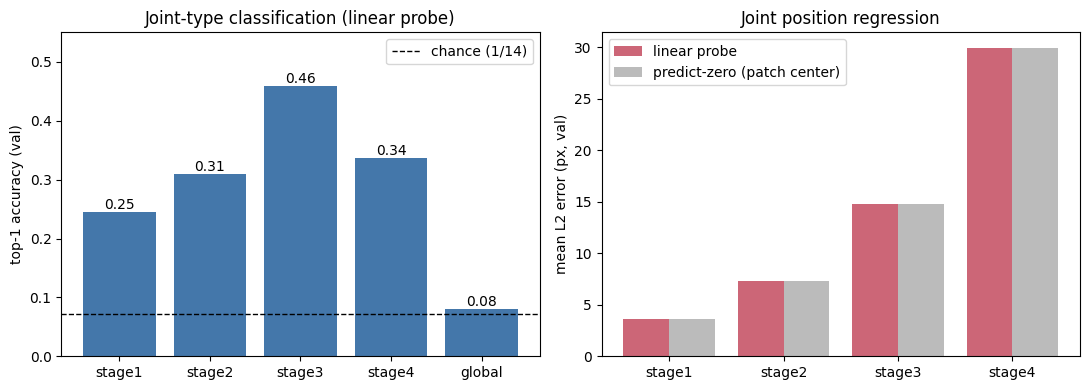

In [14]:
import matplotlib.pyplot as plt

stages = STAGE_NAMES
cls_accs = [probe_results[s]["cls"]["acc_val"] for s in stages]
reg_l2 = [probe_results[s]["reg"]["l2_val_px"] if probe_results[s]["reg"] else None
          for s in stages]
reg_zero = [probe_results[s]["reg"]["l2_zero_baseline_px"] if probe_results[s]["reg"] else None
            for s in stages]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
bars = ax.bar(stages, cls_accs, color="#4477aa")
ax.axhline(1 / 14, color="k", linestyle="--", lw=1, label="chance (1/14)")
ax.set_ylabel("top-1 accuracy (val)")
ax.set_title("Joint-type classification (linear probe)")
ax.set_ylim(0, max(cls_accs) * 1.2)
for b, v in zip(bars, cls_accs):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom")
ax.legend()

ax = axes[1]
reg_stages = [s for s in stages if probe_results[s]["reg"] is not None]
x = np.arange(len(reg_stages))
w = 0.4
probe_vals = [probe_results[s]["reg"]["l2_val_px"] for s in reg_stages]
zero_vals  = [probe_results[s]["reg"]["l2_zero_baseline_px"] for s in reg_stages]
ax.bar(x - w/2, probe_vals, w, label="linear probe", color="#cc6677")
ax.bar(x + w/2, zero_vals,  w, label="predict-zero (patch center)", color="#bbbbbb")
ax.set_xticks(x); ax.set_xticklabels(reg_stages)
ax.set_ylabel("mean L2 error (px, val)")
ax.set_title("Joint position regression")
ax.legend()
plt.tight_layout(); plt.show()


best classification stage: stage3

per-joint classification accuracy on probe-val (stage3):
  joint            idx     N    acc
  left_shoulder      0  1374  0.483
  right_shoulder     1  1367  0.481
  left_elbow         2  1197  0.403
  right_elbow        3  1168  0.414
  left_wrist         4  1123  0.275
  right_wrist        5  1097  0.315
  left_hip           6  1251  0.397
  right_hip          7  1247  0.393
  left_knee          8  1002  0.314
  right_knee         9   983  0.410
  left_ankle        10   839  0.347
  right_ankle       11   829  0.460
  head              12  1355  0.855
  neck              13  1388  0.691


/tmp/ipykernel_103251/896865189.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(names, rotation=40, ha="right")


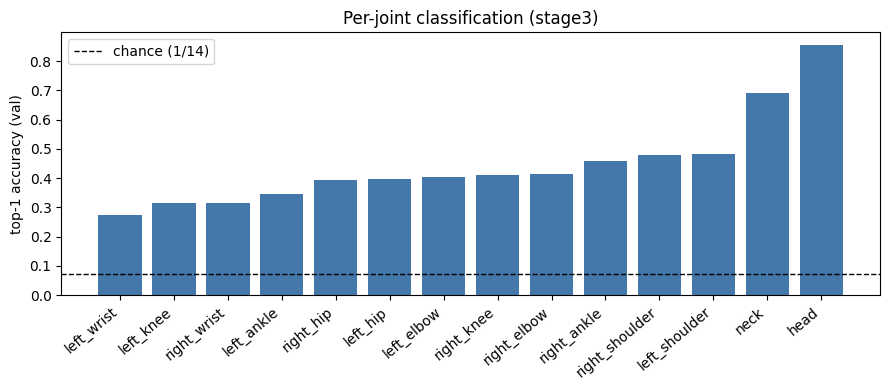

In [15]:
# Per-joint-type breakdown on the best classification stage
best_stage = max(STAGE_NAMES, key=lambda s: probe_results[s]["cls"]["acc_val"])
print(f"best classification stage: {best_stage}")

pred_va = probe_results[best_stage]["cls"]["pred_val"]
y_va = probe_data["val"]["y_cls"]

per_joint = []
for name, idx in CROWDPOSE_JOINT_NAMES.items():
    mask = y_va == idx
    n = int(mask.sum())
    acc = (pred_va[mask] == idx).float().mean().item() if n > 0 else float("nan")
    per_joint.append((name, idx, n, acc))

print(f"\nper-joint classification accuracy on probe-val ({best_stage}):")
print(f"  {'joint':16s} {'idx':>3s} {'N':>5s} {'acc':>6s}")
for name, idx, n, acc in per_joint:
    print(f"  {name:16s} {idx:3d} {n:5d} {acc:6.3f}")

# Bar chart, sorted by accuracy
per_joint_sorted = sorted(per_joint, key=lambda r: r[3])
names = [r[0] for r in per_joint_sorted]
accs  = [r[3] for r in per_joint_sorted]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(names, accs, color="#4477aa")
ax.axhline(1 / 14, color="k", linestyle="--", lw=1, label="chance (1/14)")
ax.set_xticklabels(names, rotation=40, ha="right")
ax.set_ylabel("top-1 accuracy (val)")
ax.set_title(f"Per-joint classification ({best_stage})")
ax.legend()
plt.tight_layout(); plt.show()


### Findings

**Joint-type classification (linear probe, top-1 acc on probe-val, chance = 0.071):**
- stage1 0.25 · stage2 0.31 · **stage3 0.46** · stage4 0.34 · global 0.08.
- Mid-level features (stage3, stride 16, 384ch) carry the most linearly-decodable
  joint identity. stage1 is too low-level (raw texture), stage4 is too coarse
  spatially, global has no spatial info (chance).
- Per-joint: head (0.85) and neck (0.69) are easy; wrists/knees drop to ~0.28.
  Most errors are likely left↔right-symmetric confusions and "limb-tip looks
  like another limb-tip" confusions.

**Joint position regression (mean L2 in pixels on probe-val):**
- *No stage* meaningfully beats predicting the patch center (the quantization
  floor of that stage's stride). Differences are <0.1 px everywhere.
- A linear probe over standardized DINO features cannot recover sub-patch
  joint position from these tokens alone.

**Implication for fine-grained refinement:**
- DINO ConvNeXt features encode "*what kind of body region am I looking at*"
  (linearly decodable, mid-level) but **not** "*where exactly inside this patch
  is the joint*" (linearly undecodable at any depth).
- A linear refiner head on top of these features is unlikely to help with
  precise localization. Sub-patch refinement will need either (a) a non-linear
  head, (b) cross-attention to higher-resolution features (e.g. stage1) plus
  an explicit positional prior, or (c) features from a backbone that was
  trained with a localization objective (HRNet, RTMPose).


## F — Fused-feature probe

The model's `DinoConditioner` (and `AttentionDinoConditioner._fuse_patches`)
combines stage1 (96ch, stride 4) with stage4 (768ch, stride 32) by upsampling
stage4 to stage1 resolution and concatenating per patch — i.e. an 864-d
vector per spatial location at stride 4.

Bilinearly sampling that fused map at a joint pixel is equivalent to
**concatenating bilinearly-sampled stage1 and stage4 features at the same
location**, so we can build the fused-feature probe directly from the
existing cache without re-running the backbone. The regression target uses
the stride-4 (stage1) patch center, since that's the resolution of the
fused feature map.

Goal: with stage1's localization floor, can the added stage4 semantic
channels make the linear regression actually beat that floor?


In [16]:
# Build fused features (stage1 ⊕ stage4) directly from the existing per-stage cache.
# Regression target uses stage1's patch center (stride 4 = the fused map's resolution).
for split in ("train", "val"):
    d = probe_data[split]
    if "fused" not in d:
        d["fused"] = {
            "X":     torch.cat([d["stage1"]["X"], d["stage4"]["X"]], dim=-1),
            "y_reg": d["stage1"]["y_reg"],
        }

print("fused X:    ", tuple(probe_data["train"]["fused"]["X"].shape))
print("fused y_reg:", tuple(probe_data["train"]["fused"]["y_reg"].shape))

# Train cls + reg probe on fused features
X_tr = probe_data["train"]["fused"]["X"].float()
X_va = probe_data["val"]["fused"]["X"].float()
X_tr_n, X_va_n = standardize(X_tr, X_va)

cls_res = train_linear_probe_cls(X_tr_n, y_cls_tr, X_va_n, y_cls_va, num_classes=14)

y_reg_tr = probe_data["train"]["fused"]["y_reg"].float()
y_reg_va = probe_data["val"]["fused"]["y_reg"].float()
reg_res = train_linear_probe_reg(X_tr_n, y_reg_tr, X_va_n, y_reg_va)

probe_results["fused"] = {"cls": cls_res, "reg": reg_res, "C": X_tr.shape[1]}
print(
    f"fused   C={X_tr.shape[1]:4d}  cls_acc={cls_res['acc_val']:.3f}  "
    f"reg_L2={reg_res['l2_val_px']:.2f}px  (zero={reg_res['l2_zero_baseline_px']:.2f}px)"
)

# Side-by-side comparison with stage1 and stage4
print("\nComparison (probe-val):")
print(f"  {'feat':10s} {'C':>4s}  {'cls_acc':>8s}  {'reg_L2':>7s}  {'zero':>6s}")
for s in ("stage1", "stage4", "fused"):
    r = probe_results[s]
    print(f"  {s:10s} {r['C']:4d}  {r['cls']['acc_val']:8.3f}  "
          f"{r['reg']['l2_val_px']:7.2f}  {r['reg']['l2_zero_baseline_px']:6.2f}")


fused X:     (60704, 864)
fused y_reg: (60704, 2)
fused   C= 864  cls_acc=0.393  reg_L2=3.69px  (zero=3.65px)

Comparison (probe-val):
  feat          C   cls_acc   reg_L2    zero
  stage1       96     0.246     3.65    3.65
  stage4      768     0.336    29.94   29.88
  fused       864     0.393     3.69    3.65


## G — Offset visualizations

Three views to make the regression behavior concrete:
1. **Predicted vs GT offset scatter** for stage1, stage3, fused. If the
   probe were learning, points would sit on the y=x diagonal. If it
   collapses to the patch center, predictions cluster at the origin.
2. **Per-joint regression L2** bars: probe vs predict-zero baseline,
   for stage1 and fused, broken down by joint type.
3. **Quiver overlay** on one validation image showing GT joint locations,
   the GT offset (patch center → GT joint), and the predicted offset,
   for stage1 and fused.


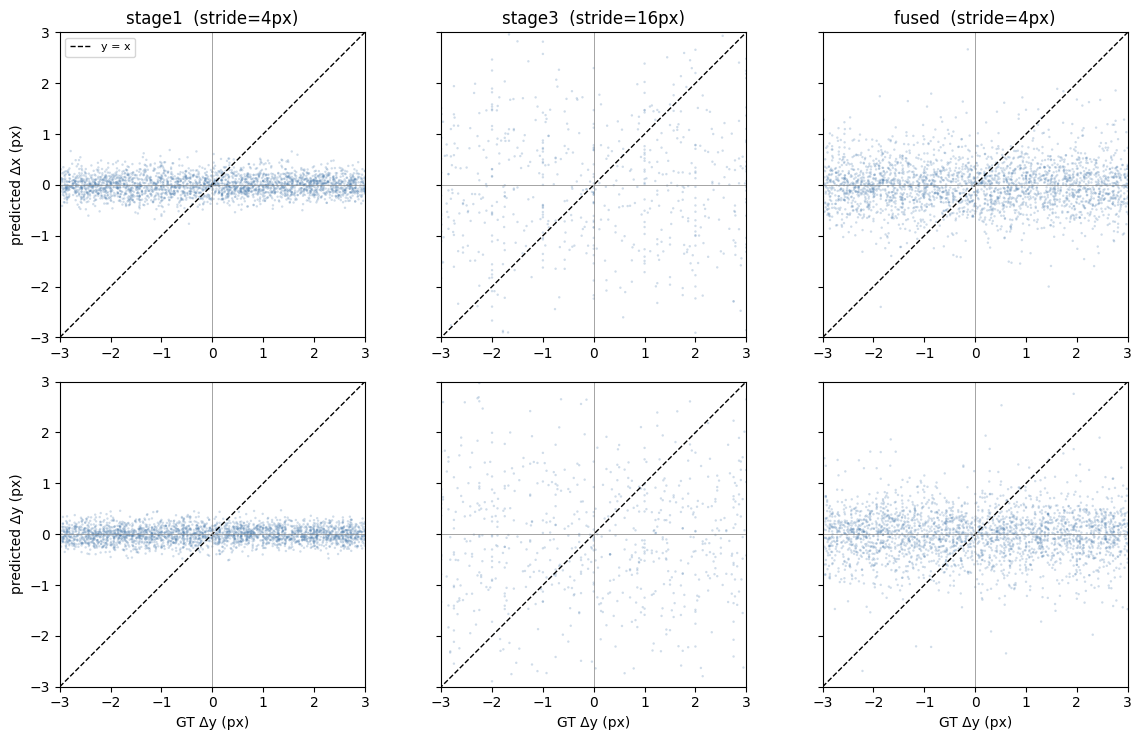

In [17]:
# 1) Predicted vs GT offset scatter (probe-val) for stage1, stage3, fused.
SCATTER_STAGES = ["stage1", "stage3", "fused"]
N_SCATTER = 4000  # subsample so the plot is readable

rng_plot = np.random.default_rng(0)
sel = rng_plot.choice(probe_data["val"]["y_cls"].shape[0],
                      size=min(N_SCATTER, probe_data["val"]["y_cls"].shape[0]),
                      replace=False)

fig, axes = plt.subplots(2, len(SCATTER_STAGES), figsize=(4 * len(SCATTER_STAGES), 7.5),
                         sharex="row", sharey="row")
for col, stage in enumerate(SCATTER_STAGES):
    pred = probe_results[stage]["reg"]["pred_val"].numpy()[sel]
    gt   = probe_data["val"][stage]["y_reg"].numpy()[sel]
    stride = STAGE_STRIDES[stage] if stage in STAGE_STRIDES else STAGE_STRIDES["stage1"]
    lim = stride * 0.75  # patch covers ±stride/2; show a bit beyond

    for row, axis_label in enumerate(("Δx", "Δy")):
        ax = axes[row, col]
        ax.scatter(gt[:, row], pred[:, row], s=3, alpha=0.25, c="#4477aa", edgecolors="none")
        ax.plot([-lim, lim], [-lim, lim], "k--", lw=1, label="y = x")
        ax.axhline(0, color="gray", lw=0.5)
        ax.axvline(0, color="gray", lw=0.5)
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
        ax.set_aspect("equal", adjustable="box")
        if row == 0:
            ax.set_title(f"{stage}  (stride={stride}px)")
        if col == 0:
            ax.set_ylabel(f"predicted {axis_label} (px)")
        if row == 1:
            ax.set_xlabel(f"GT {axis_label} (px)")
        if row == 0 and col == 0:
            ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()


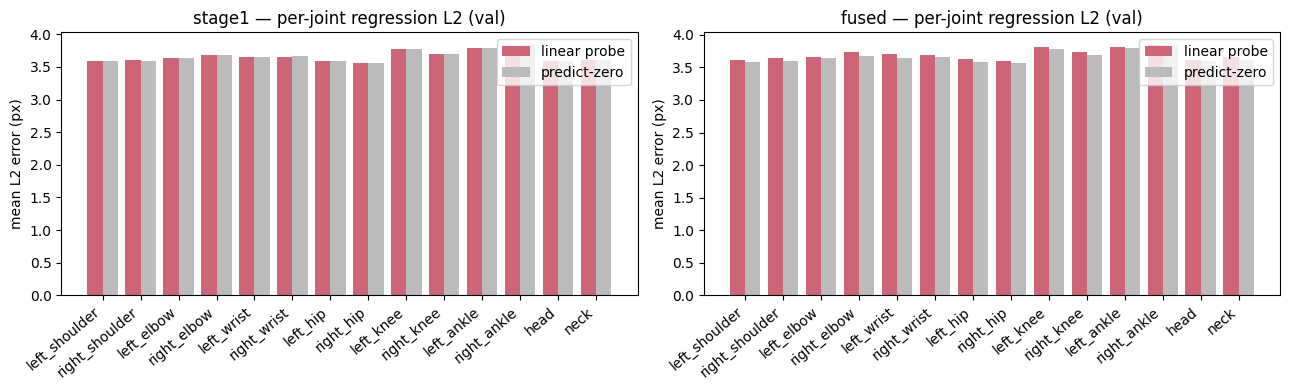

In [18]:
# 2) Per-joint regression L2 (probe vs predict-zero) for stage1 and fused.
JOINT_NAMES = list(CROWDPOSE_JOINT_NAMES.keys())
y_va_cls = probe_data["val"]["y_cls"].numpy()

def per_joint_l2(stage: str) -> tuple[np.ndarray, np.ndarray]:
    pred = probe_results[stage]["reg"]["pred_val"].numpy()
    gt   = probe_data["val"][stage]["y_reg"].numpy()
    err_probe = np.linalg.norm(pred - gt, axis=-1)
    err_zero  = np.linalg.norm(gt, axis=-1)
    out_probe = np.zeros(14); out_zero = np.zeros(14)
    for idx in range(14):
        m = y_va_cls == idx
        out_probe[idx] = err_probe[m].mean() if m.any() else np.nan
        out_zero[idx]  = err_zero[m].mean()  if m.any() else np.nan
    return out_probe, out_zero

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
for ax, stage in zip(axes, ("stage1", "fused")):
    probe_l2, zero_l2 = per_joint_l2(stage)
    x = np.arange(14); w = 0.4
    ax.bar(x - w/2, probe_l2, w, color="#cc6677", label="linear probe")
    ax.bar(x + w/2, zero_l2,  w, color="#bbbbbb", label="predict-zero")
    ax.set_xticks(x); ax.set_xticklabels(JOINT_NAMES, rotation=40, ha="right")
    ax.set_title(f"{stage} — per-joint regression L2 (val)")
    ax.set_ylabel("mean L2 error (px)")
    ax.legend()
plt.tight_layout(); plt.show()


In [19]:
# 3) Quiver overlay on one probe-val image.
# We refit the stage1 and fused regressors here so we can apply them to a single
# image's freshly-sampled features (the saved pred_val is one big tensor without
# image attribution beyond probe_data["val"]["image_id"]).

def fit_linear_regressor(X_tr_n: torch.Tensor, y_tr: torch.Tensor) -> torch.nn.Linear:
    torch.manual_seed(PROBE_SEED)
    gen = torch.Generator().manual_seed(PROBE_SEED)
    C = X_tr_n.shape[1]
    model = torch.nn.Linear(C, 2).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=PROBE_LR, weight_decay=PROBE_WD)
    X_d, y_d = X_tr_n.to(DEVICE), y_tr.to(DEVICE)
    N = X_tr_n.shape[0]
    for _ in range(PROBE_EPOCHS):
        for idx in _iter_minibatches(N, PROBE_BATCH_SIZE, gen):
            loss = F.mse_loss(model(X_d[idx]), y_d[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    return model.eval()

# Compute and cache per-feature standardization stats and refit regressors
stage1_X_tr = probe_data["train"]["stage1"]["X"].float()
stage1_X_va = probe_data["val"]["stage1"]["X"].float()
stage1_mean = stage1_X_tr.mean(dim=0, keepdim=True)
stage1_std  = stage1_X_tr.std(dim=0, keepdim=True).clamp_min(1e-6)
stage1_reg_model = fit_linear_regressor(
    (stage1_X_tr - stage1_mean) / stage1_std,
    probe_data["train"]["stage1"]["y_reg"].float(),
)

fused_X_tr = probe_data["train"]["fused"]["X"].float()
fused_mean = fused_X_tr.mean(dim=0, keepdim=True)
fused_std  = fused_X_tr.std(dim=0, keepdim=True).clamp_min(1e-6)
fused_reg_model = fit_linear_regressor(
    (fused_X_tr - fused_mean) / fused_std,
    probe_data["train"]["fused"]["y_reg"].float(),
)
print("refit done")


refit done


In [20]:
VIS_DS_INDEX = split_indices["val"][0]
vis_sample = dataset[VIS_DS_INDEX]
vis_pil = Image.open(vis_sample["img_path"]).convert("RGB")

kpts_all = vis_sample["keypoints"].reshape(-1, 2)
vis_flat = vis_sample["visibility"].reshape(-1)
keep_mask = vis_flat > 0
kpts_visible = kpts_all[keep_mask].to(DEVICE)
joint_idx_template = torch.arange(14, dtype=torch.long).repeat(vis_sample["keypoints"].shape[0])
joint_ids = joint_idx_template[keep_mask].numpy()

vis_feats = extract_stage_features(vis_pil)

# Sample stage1 and stage4 features at the GT joint positions (stride-4 patch center)
stage1_feat, patch_xy = sample_at_joints(
    vis_feats["stage1"], kpts_visible, vis_feats["orig_hw"], vis_feats["resized_hw"],
)
stage4_feat, _ = sample_at_joints(
    vis_feats["stage4"], kpts_visible, vis_feats["orig_hw"], vis_feats["resized_hw"],
)
fused_feat = torch.cat([stage1_feat, stage4_feat], dim=-1)

# Standardize using the cached stats then run the refit regressors
stage1_n = ((stage1_feat.cpu() - stage1_mean) / stage1_std).to(DEVICE)
fused_n  = ((fused_feat.cpu()  - fused_mean)  / fused_std ).to(DEVICE)
with torch.no_grad():
    stage1_pred = stage1_reg_model(stage1_n).cpu().numpy()
    fused_pred  = fused_reg_model(fused_n).cpu().numpy()

patch_np = patch_xy.cpu().numpy()
gt_np    = kpts_visible.cpu().numpy()
gt_off   = gt_np - patch_np  # actual offset patch_center → GT joint

print(f"image_id={vis_sample['image_id']}  visible joints={len(joint_ids)}")
print(f"GT |off|     mean={np.linalg.norm(gt_off, axis=-1).mean():.2f}px")
print(f"stage1 pred  mean={np.linalg.norm(stage1_pred, axis=-1).mean():.2f}px")
print(f"fused  pred  mean={np.linalg.norm(fused_pred,  axis=-1).mean():.2f}px")


image_id=117659  visible joints=24
GT |off|     mean=4.16px
stage1 pred  mean=0.14px
fused  pred  mean=0.52px


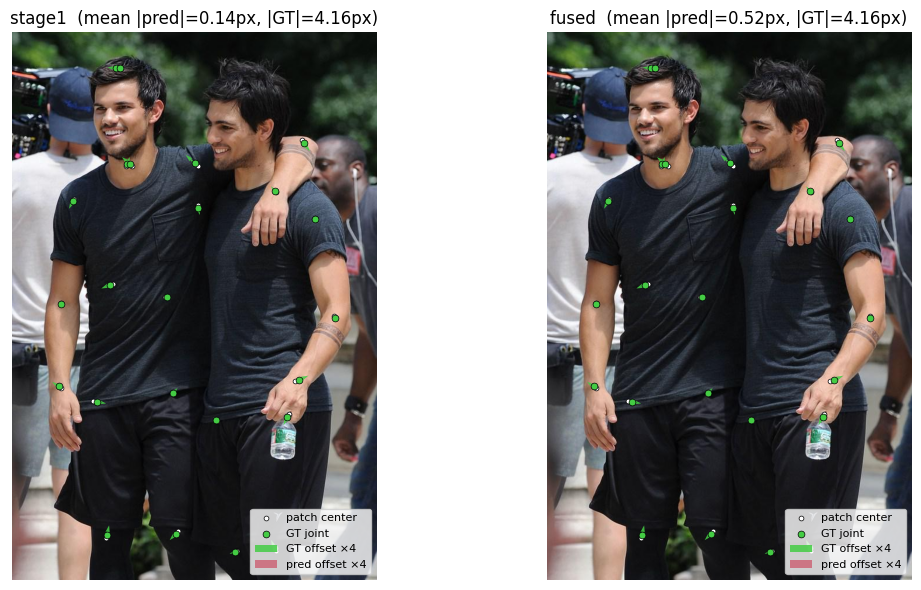

In [21]:
ARROW_SCALE = 4.0  # visualization gain on offsets (offsets are tiny vs. image size)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, (name, pred) in zip(axes, [("stage1", stage1_pred), ("fused", fused_pred)]):
    ax.imshow(vis_pil)
    # patch centers (small grey dots)
    ax.scatter(patch_np[:, 0], patch_np[:, 1], s=12, c="white",
               edgecolors="black", linewidths=0.5, zorder=3, label="patch center")
    # GT joints
    ax.scatter(gt_np[:, 0], gt_np[:, 1], s=24, c="#44cc44",
               edgecolors="black", linewidths=0.5, zorder=4, label="GT joint")
    # GT offset arrows (patch center → GT), magnified
    ax.quiver(patch_np[:, 0], patch_np[:, 1],
              gt_off[:, 0] * ARROW_SCALE, gt_off[:, 1] * ARROW_SCALE,
              angles="xy", scale_units="xy", scale=1, color="#44cc44",
              width=0.004, alpha=0.85, label=f"GT offset ×{ARROW_SCALE:g}")
    # Predicted offset arrows (patch center → patch_center+pred), magnified
    ax.quiver(patch_np[:, 0], patch_np[:, 1],
              pred[:, 0] * ARROW_SCALE, pred[:, 1] * ARROW_SCALE,
              angles="xy", scale_units="xy", scale=1, color="#cc6677",
              width=0.004, alpha=0.85, label=f"pred offset ×{ARROW_SCALE:g}")
    ax.set_title(f"{name}  (mean |pred|={np.linalg.norm(pred, axis=-1).mean():.2f}px, "
                 f"|GT|={np.linalg.norm(gt_off, axis=-1).mean():.2f}px)")
    ax.set_axis_off()
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()


### Findings (fused + visualizations)

- **Fused (stage1 ⊕ stage4, 864-d) does not match stage1's regression**:
  fused 3.69 px vs stage1 3.65 px vs predict-zero baseline 3.65 px on
  probe-val. The added stage4 channels make generalization slightly worse
  (more parameters, no extra localization signal).
- **Classification on fused = 0.39** sits between stage1 (0.25) and
  stage3 (0.46): combining stage1+stage4 helps semantics modestly but
  doesn't reach the best mid-level stage.
- **Scatter plots**: every stage's predictions collapse to a horizontal
  stripe at predicted-offset ≈ 0; the y=x diagonal is unpopulated.
  The linear probe converges on the trivial "output 0" solution.
- **Per-joint bars**: probe ≈ predict-zero for every joint type, both
  stage1 and fused. The failure is uniform across joint types, not a
  hard-vs-easy joint issue.
- **Quiver overlay** on a probe-val image: GT mean offset 4.16 px,
  predicted mean offset 0.14 px (stage1) and 0.52 px (fused) — predicted
  arrows are invisible at ×4 magnification next to GT arrows.

**Takeaway:** the model's `DinoConditioner` fusion is a re-mix of the same
features and inherits stage1's *complete absence* of linearly-decodable
sub-patch position signal. To get fine-grained refinement out of these
features we either need (a) the trained `AttentionDinoConditioner` to
extract it non-linearly, (b) a localization-trained backbone, or
(c) features from an explicit positional channel (e.g. a fixed
sinusoidal/coordinate map appended to the DINO features).


## H — Spatial-resolution grid

To make the per-stage resolution concrete, we visualize on the same
probe-val image used in the quiver overlay:

- **Top row**: image with every stage's patch-center grid overlaid
  (`stage1` ≈ stride 4, `stage2` ≈ 8, `stage3` ≈ 16, `stage4` ≈ 32).
- **Bottom row**: image with a PCA-to-RGB visualization of that stage's
  feature map, upsampled to image resolution with nearest-neighbor so
  patch boundaries are visible.

`global` has no spatial info and is omitted.


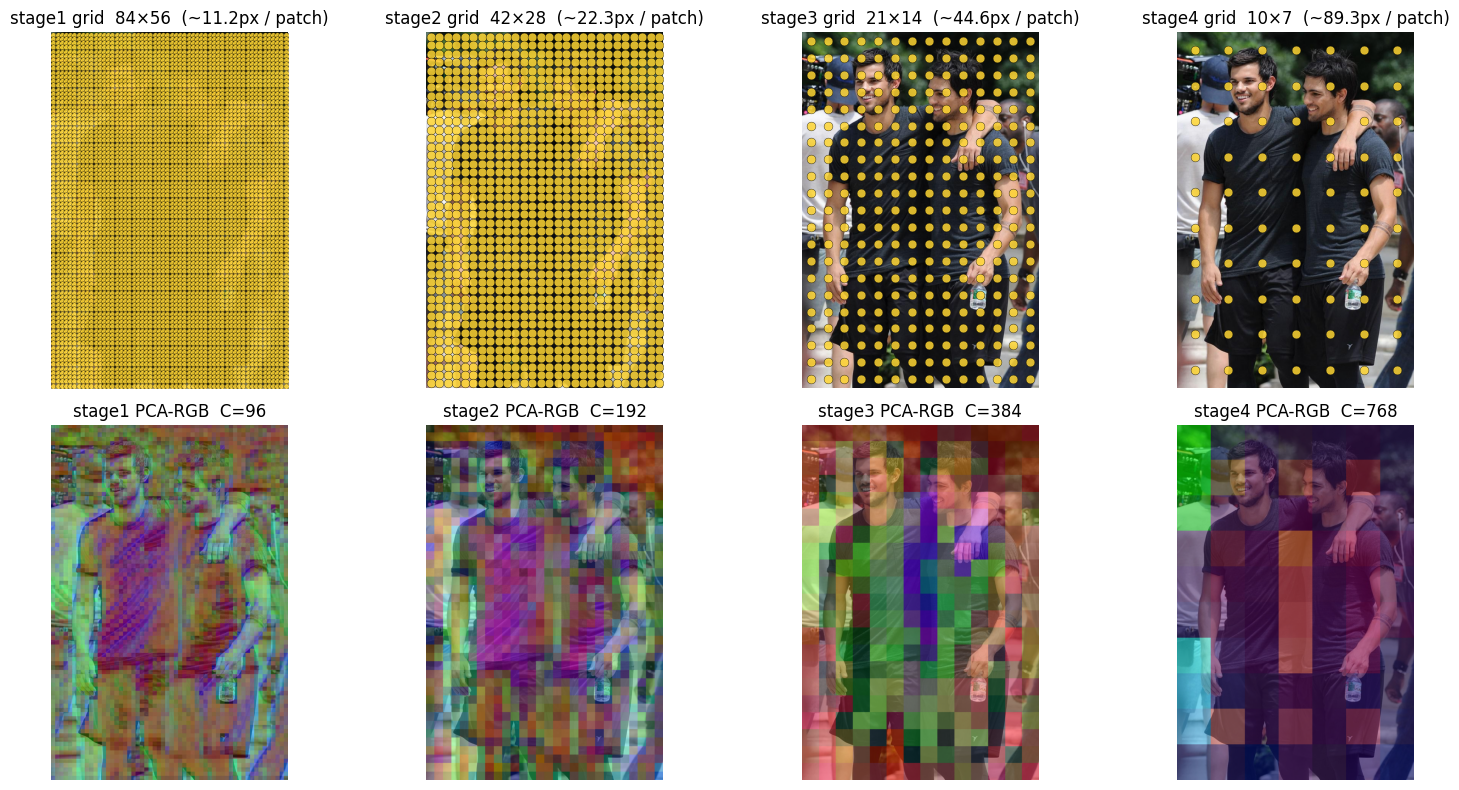

In [22]:
def feature_map_to_pca_rgb(feat_map: torch.Tensor) -> np.ndarray:
    """(C, H, W) -> (H, W, 3) in [0, 1] via PCA on the channel dim."""
    C, H, W = feat_map.shape
    flat = feat_map.reshape(C, H * W).T.float()                 # (HW, C)
    flat = flat - flat.mean(dim=0, keepdim=True)
    # top-3 right singular vectors via SVD
    _, _, vh = torch.linalg.svd(flat, full_matrices=False)
    pcs = flat @ vh[:3].T                                       # (HW, 3)
    pcs = pcs.reshape(H, W, 3)
    p_lo = torch.quantile(pcs.reshape(-1, 3), 0.02, dim=0)
    p_hi = torch.quantile(pcs.reshape(-1, 3), 0.98, dim=0)
    rgb = ((pcs - p_lo) / (p_hi - p_lo).clamp_min(1e-6)).clamp(0, 1)
    return rgb.cpu().numpy()


GRID_STAGES = ["stage1", "stage2", "stage3", "stage4"]
Wo, Ho = vis_pil.width, vis_pil.height
Hr, Wr = vis_feats["resized_hw"]

fig, axes = plt.subplots(2, len(GRID_STAGES), figsize=(4 * len(GRID_STAGES), 8))
for col, stage in enumerate(GRID_STAGES):
    feat = vis_feats[stage]                  # (C, Hs, Ws) on DEVICE
    C, Hs, Ws = feat.shape

    # patch centers in original-image pixel coords
    sx = Wr / Ws; sy = Hr / Hs
    xs = (torch.arange(Ws) + 0.5) * sx * (Wo / Wr)
    ys = (torch.arange(Hs) + 0.5) * sy * (Ho / Hr)
    gx, gy = torch.meshgrid(xs, ys, indexing="xy")
    cx = gx.numpy().ravel(); cy = gy.numpy().ravel()
    eff_stride = sx * (Wo / Wr)              # px between adjacent patch centers in orig image

    # Top: image + patch-center grid
    ax = axes[0, col]
    ax.imshow(vis_pil)
    marker_size = max(1.0, min(40.0, (eff_stride * 0.35) ** 2))
    ax.scatter(cx, cy, s=marker_size, c="#ffd633",
               edgecolors="black", linewidths=0.3, alpha=0.85)
    ax.set_title(f"{stage} grid  {Hs}×{Ws}  (~{eff_stride:.1f}px / patch)")
    ax.set_axis_off()

    # Bottom: PCA-RGB feature map upsampled to image resolution
    ax = axes[1, col]
    rgb = feature_map_to_pca_rgb(feat)        # (Hs, Ws, 3)
    rgb_up = np.array(Image.fromarray((rgb * 255).astype(np.uint8))
                       .resize((Wo, Ho), resample=Image.NEAREST))
    ax.imshow(vis_pil); ax.imshow(rgb_up, alpha=0.55)
    ax.set_title(f"{stage} PCA-RGB  C={C}")
    ax.set_axis_off()

plt.tight_layout(); plt.show()


## I — MLP probe (non-linear)

Bound the non-linear gain over the linear probe with a shallow MLP:
`Linear(C, 256) → GELU → Dropout(0.1) → Linear(256, out_dim)`,
trained with AdamW lr=1e-3, wd=1e-4, batch=4096, 30 epochs, seed=0.

Run on `stage1`, `stage3`, `fused` (the three feature variants used for the
linear probe), for both joint-type classification and joint-position
regression. We reuse the standardized features and the cached `y_cls`/`y_reg`,
so numbers are directly comparable to Section D/F.

Question: does adding a non-linearity recover the sub-patch localization
signal that the linear probe missed, or does the regression floor persist?


In [23]:
MLP_HIDDEN = 256
MLP_DROPOUT = 0.1
MLP_EPOCHS = 30
MLP_LR = 1e-3
MLP_WD = 1e-4
MLP_BATCH = 4096
MLP_STAGES = ["stage1", "stage3", "fused"]


class MLPProbe(torch.nn.Module):
    def __init__(self, in_dim: int, hidden: int, out_dim: int, dropout: float):
        super().__init__()
        self.net = torch.nn.Sequential(
            torch.nn.Linear(in_dim, hidden),
            torch.nn.GELU(),
            torch.nn.Dropout(dropout),
            torch.nn.Linear(hidden, out_dim),
        )

    def forward(self, x):
        return self.net(x)


def _train_mlp(
    X_tr: torch.Tensor, y_tr: torch.Tensor,
    X_va: torch.Tensor, y_va: torch.Tensor,
    out_dim: int, loss_fn,
) -> tuple[torch.nn.Module, torch.Tensor]:
    torch.manual_seed(PROBE_SEED)
    gen = torch.Generator().manual_seed(PROBE_SEED)
    model = MLPProbe(X_tr.shape[1], MLP_HIDDEN, out_dim, MLP_DROPOUT).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=MLP_LR, weight_decay=MLP_WD)
    X_tr_d, y_tr_d = X_tr.to(DEVICE), y_tr.to(DEVICE)
    X_va_d         = X_va.to(DEVICE)
    N = X_tr.shape[0]
    for _ in range(MLP_EPOCHS):
        model.train()
        for idx in _iter_minibatches(N, MLP_BATCH, gen):
            pred = model(X_tr_d[idx])
            loss = loss_fn(pred, y_tr_d[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        out_va = model(X_va_d).cpu()
    return model, out_va


def train_mlp_probe_cls(X_tr, y_tr, X_va, y_va, num_classes):
    _, out_va = _train_mlp(X_tr, y_tr, X_va, y_va, num_classes, F.cross_entropy)
    pred_va = out_va.argmax(dim=-1)
    return {"acc_val": (pred_va == y_va).float().mean().item(), "pred_val": pred_va}


def train_mlp_probe_reg(X_tr, y_tr, X_va, y_va):
    _, pred_va = _train_mlp(X_tr, y_tr, X_va, y_va, 2, F.mse_loss)
    return {
        "l2_val_px":           (pred_va - y_va).norm(dim=-1).mean().item(),
        "l2_zero_baseline_px": y_va.norm(dim=-1).mean().item(),
        "pred_val":            pred_va,
    }


mlp_results = {}
for stage in MLP_STAGES:
    X_tr = probe_data["train"][stage]["X"].float()
    X_va = probe_data["val"][stage]["X"].float()
    X_tr_n, X_va_n = standardize(X_tr, X_va)

    cls_res = train_mlp_probe_cls(X_tr_n, y_cls_tr, X_va_n, y_cls_va, num_classes=14)

    y_reg_tr = probe_data["train"][stage]["y_reg"].float()
    y_reg_va = probe_data["val"][stage]["y_reg"].float()
    reg_res = train_mlp_probe_reg(X_tr_n, y_reg_tr, X_va_n, y_reg_va)

    mlp_results[stage] = {"cls": cls_res, "reg": reg_res, "C": X_tr.shape[1]}
    print(
        f"{stage:7s} C={X_tr.shape[1]:4d}  "
        f"cls_acc={cls_res['acc_val']:.3f}  "
        f"reg_L2={reg_res['l2_val_px']:.2f}px  "
        f"(zero={reg_res['l2_zero_baseline_px']:.2f}px)"
    )

print("\nLinear vs MLP comparison (probe-val):")
print(f"  {'feat':8s}  {'cls_lin':>7s}  {'cls_mlp':>7s}  "
      f"{'reg_lin':>7s}  {'reg_mlp':>7s}  {'zero':>6s}")
for s in MLP_STAGES:
    lin = probe_results[s]
    mlp = mlp_results[s]
    print(f"  {s:8s}  {lin['cls']['acc_val']:7.3f}  {mlp['cls']['acc_val']:7.3f}  "
          f"{lin['reg']['l2_val_px']:7.2f}  {mlp['reg']['l2_val_px']:7.2f}  "
          f"{lin['reg']['l2_zero_baseline_px']:6.2f}")


stage1  C=  96  cls_acc=0.280  reg_L2=3.46px  (zero=3.65px)
stage3  C= 384  cls_acc=0.497  reg_L2=14.94px  (zero=14.76px)
fused   C= 864  cls_acc=0.430  reg_L2=3.74px  (zero=3.65px)

Linear vs MLP comparison (probe-val):
  feat      cls_lin  cls_mlp  reg_lin  reg_mlp    zero
  stage1      0.246    0.280     3.65     3.46    3.65
  stage3      0.459    0.497    14.78    14.94   14.76
  fused       0.393    0.430     3.69     3.74    3.65


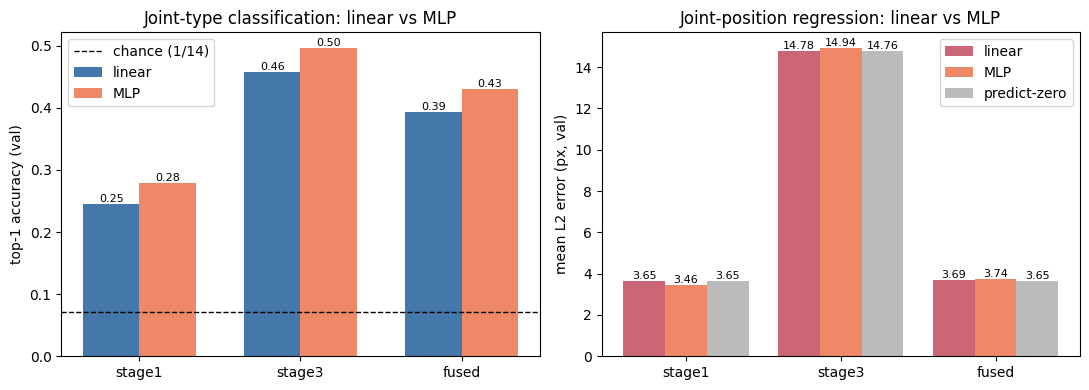

In [24]:
# Linear vs MLP comparison bar chart
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

x = np.arange(len(MLP_STAGES))
w = 0.35

ax = axes[0]
lin_acc = [probe_results[s]["cls"]["acc_val"] for s in MLP_STAGES]
mlp_acc = [mlp_results[s]["cls"]["acc_val"] for s in MLP_STAGES]
ax.bar(x - w/2, lin_acc, w, color="#4477aa", label="linear")
ax.bar(x + w/2, mlp_acc, w, color="#ee8866", label="MLP")
ax.axhline(1 / 14, color="k", linestyle="--", lw=1, label="chance (1/14)")
ax.set_xticks(x); ax.set_xticklabels(MLP_STAGES)
ax.set_ylabel("top-1 accuracy (val)")
ax.set_title("Joint-type classification: linear vs MLP")
for xi, (lv, mv) in enumerate(zip(lin_acc, mlp_acc)):
    ax.text(xi - w/2, lv, f"{lv:.2f}", ha="center", va="bottom", fontsize=8)
    ax.text(xi + w/2, mv, f"{mv:.2f}", ha="center", va="bottom", fontsize=8)
ax.legend()

ax = axes[1]
lin_l2 = [probe_results[s]["reg"]["l2_val_px"] for s in MLP_STAGES]
mlp_l2 = [mlp_results[s]["reg"]["l2_val_px"] for s in MLP_STAGES]
zero_l2 = [probe_results[s]["reg"]["l2_zero_baseline_px"] for s in MLP_STAGES]
w3 = 0.27
ax.bar(x - w3, lin_l2,  w3, color="#cc6677", label="linear")
ax.bar(x,      mlp_l2,  w3, color="#ee8866", label="MLP")
ax.bar(x + w3, zero_l2, w3, color="#bbbbbb", label="predict-zero")
ax.set_xticks(x); ax.set_xticklabels(MLP_STAGES)
ax.set_ylabel("mean L2 error (px, val)")
ax.set_title("Joint-position regression: linear vs MLP")
for xi, (lv, mv, zv) in enumerate(zip(lin_l2, mlp_l2, zero_l2)):
    ax.text(xi - w3, lv, f"{lv:.2f}", ha="center", va="bottom", fontsize=8)
    ax.text(xi,      mv, f"{mv:.2f}", ha="center", va="bottom", fontsize=8)
    ax.text(xi + w3, zv, f"{zv:.2f}", ha="center", va="bottom", fontsize=8)
ax.legend()
plt.tight_layout(); plt.show()


## J — Trained `AttentionDinoConditioner` probe

The previous sections probe the **frozen** DINO features. Here we probe the
**trained** patch tokens of our +MP refiner: load `AttentionDinoConditioner`
from the checkpoint, run its `_fuse_patches` (the learned MLP that fuses
stage1 + upsampled-stage4 → `inner_dim`-d tokens at stage-1 resolution),
and sample those tokens at every visible GT joint.

We then run the same linear and MLP probes on these features and compare to
the frozen `fused` baseline. If training reshapes the features to expose
joint identity / sub-patch position, we should see a measurable jump.

Checkpoint: `results/sweeps/arch-message-passing/task_1/20260316_003813/...`


In [25]:
# Load trained AttentionDinoConditioner from the +MP checkpoint
from scripts.benchmark_diffusion_refiner import load_module
from src.model import AttentionDinoConditioner

CKPT_MP   = Path("results/sweeps/arch-message-passing/task_1/20260316_003813/checkpoints/epoch140-running_loss_5=0.0155.ckpt")
PRED_CACHE = "results/cache/rtmpose-m_crowdpose_val_predictions.pkl"

trained_module = load_module(
    checkpoint_path=CKPT_MP,
    run_dir=CKPT_MP.parent.parent,
    pred_cache=PRED_CACHE,
    ann_file=ANN_PATH,
    dino_cache_override=None,
    batch_size=64,
    device=DEVICE,
)
trained_cond = trained_module.dino_conditioner
assert isinstance(trained_cond, AttentionDinoConditioner), type(trained_cond)
trained_cond.eval()
for p in trained_cond.parameters():
    p.requires_grad_(False)
print(f"trained conditioner: inner_dim={trained_cond.inner_dim}  num_heads={trained_cond.num_heads}")


loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
loading annotations into memory...
Done (t=0.05s)
creating index...
index created!
DinoConditioner: registered 3 cache dir(s)
trained conditioner: inner_dim=256  num_heads=4


In [26]:
# Build trained-conditioner probe dataset.
# We feed our existing backbone's stage1 + stage4 maps through trained_cond._fuse_patches,
# reshape to (inner_dim, H_s, W_s), and reuse sample_at_joints. Regression target = stage1
# patch center (same as fused), so we copy y_reg from stage1.
TRAINED_CACHE = {split: CACHE_DIR / f"trained_cond_{split}.pt" for split in ("train", "val")}


@torch.no_grad()
def build_trained_split(image_indices: list[int]) -> dict:
    X_all, yreg_all, ycls_all = [], [], []
    K = 14
    joint_idx_template = torch.arange(K, dtype=torch.long)
    for ds_idx in tqdm(image_indices, desc="trained-cond extract"):
        sample = dataset[ds_idx]
        kpts = sample["keypoints"]
        vis  = sample["visibility"]
        N = kpts.shape[0]
        kpts_flat = kpts.reshape(-1, 2)
        vis_flat  = vis.reshape(-1)
        joint_id  = joint_idx_template.repeat(N)
        keep      = vis_flat > 0
        if keep.sum() == 0:
            continue
        kpts_vis = kpts_flat[keep].to(DEVICE)
        y_cls    = joint_id[keep]

        pil_img = Image.open(sample["img_path"]).convert("RGB")
        feats = extract_stage_features(pil_img)
        spatial_map  = feats["stage1"]   # (96, H_s, W_s)
        semantic_map = feats["stage4"]   # (768, h_s, w_s)

        patch_feats, _ = trained_cond._fuse_patches(spatial_map, semantic_map)  # (P, inner_dim)
        C_s, H_s, W_s = spatial_map.shape
        # (inner_dim, H_s, W_s) for sample_at_joints
        feat_map = patch_feats.T.reshape(trained_cond.inner_dim, H_s, W_s).contiguous()

        sampled, patch_xy = sample_at_joints(
            feat_map, kpts_vis, feats["orig_hw"], feats["resized_hw"],
        )
        X_all.append(sampled.cpu())
        yreg_all.append((kpts_vis - patch_xy).cpu())
        ycls_all.append(y_cls)

    return {
        "X":     torch.cat(X_all,    dim=0),
        "y_reg": torch.cat(yreg_all, dim=0),
        "y_cls": torch.cat(ycls_all, dim=0),
    }


FORCE_REBUILD_TRAINED = False
trained_data: dict[str, dict] = {}
for split, indices in split_indices.items():
    cache_path = TRAINED_CACHE[split]
    if cache_path.exists() and not FORCE_REBUILD_TRAINED:
        print(f"[{split}] loading cached → {cache_path}")
        trained_data[split] = torch.load(cache_path, weights_only=False)
    else:
        print(f"[{split}] building from {len(indices)} images …")
        trained_data[split] = build_trained_split(indices)
        torch.save(trained_data[split], cache_path)
        print(f"[{split}] cached → {cache_path}")

for split, d in trained_data.items():
    print(f"{split}  X={tuple(d['X'].shape)}  y_reg={tuple(d['y_reg'].shape)}")


[train] building from 1600 images …


trained-cond extract:   0%|          | 0/1600 [00:00<?, ?it/s]

[train] cached → results/cache/dino_probe/trained_cond_train.pt
[val] building from 400 images …


trained-cond extract:   0%|          | 0/400 [00:00<?, ?it/s]

[val] cached → results/cache/dino_probe/trained_cond_val.pt
train  X=(60704, 256)  y_reg=(60704, 2)
val  X=(16220, 256)  y_reg=(16220, 2)


In [27]:
# Train linear + MLP probe on trained-conditioner features
X_tr_t = trained_data["train"]["X"].float()
X_va_t = trained_data["val"]["X"].float()
y_cls_tr_t = trained_data["train"]["y_cls"]
y_cls_va_t = trained_data["val"]["y_cls"]
y_reg_tr_t = trained_data["train"]["y_reg"].float()
y_reg_va_t = trained_data["val"]["y_reg"].float()

# Sanity: probe-cls labels must match across feature variants
assert torch.equal(y_cls_tr_t, y_cls_tr) and torch.equal(y_cls_va_t, y_cls_va), \
    "y_cls mismatch — split or visibility filter changed"

X_tr_n_t, X_va_n_t = standardize(X_tr_t, X_va_t)

# Linear
lin_cls_t = train_linear_probe_cls(X_tr_n_t, y_cls_tr_t, X_va_n_t, y_cls_va_t, num_classes=14)
lin_reg_t = train_linear_probe_reg(X_tr_n_t, y_reg_tr_t, X_va_n_t, y_reg_va_t)

# MLP
mlp_cls_t = train_mlp_probe_cls(X_tr_n_t, y_cls_tr_t, X_va_n_t, y_cls_va_t, num_classes=14)
mlp_reg_t = train_mlp_probe_reg(X_tr_n_t, y_reg_tr_t, X_va_n_t, y_reg_va_t)

probe_results["trained_cond"] = {"cls": lin_cls_t, "reg": lin_reg_t, "C": X_tr_t.shape[1]}
mlp_results  ["trained_cond"] = {"cls": mlp_cls_t, "reg": mlp_reg_t, "C": X_tr_t.shape[1]}

print("trained_cond  C=256")
print(f"  linear  cls_acc={lin_cls_t['acc_val']:.3f}  reg_L2={lin_reg_t['l2_val_px']:.2f}px")
print(f"  MLP     cls_acc={mlp_cls_t['acc_val']:.3f}  reg_L2={mlp_reg_t['l2_val_px']:.2f}px")
print(f"  zero baseline reg_L2={lin_reg_t['l2_zero_baseline_px']:.2f}px")

# Full comparison: stage1 / stage3 / fused (frozen) vs trained_cond
print("\nFull comparison (probe-val):")
print(f"  {'feat':14s}  {'cls_lin':>7s}  {'cls_mlp':>7s}  "
      f"{'reg_lin':>7s}  {'reg_mlp':>7s}  {'zero':>6s}")
for s in ["stage1", "stage3", "fused", "trained_cond"]:
    lin = probe_results[s]; mlp = mlp_results[s]
    print(f"  {s:14s}  {lin['cls']['acc_val']:7.3f}  {mlp['cls']['acc_val']:7.3f}  "
          f"{lin['reg']['l2_val_px']:7.2f}  {mlp['reg']['l2_val_px']:7.2f}  "
          f"{lin['reg']['l2_zero_baseline_px']:6.2f}")


trained_cond  C=256
  linear  cls_acc=0.315  reg_L2=3.66px
  MLP     cls_acc=0.339  reg_L2=3.66px
  zero baseline reg_L2=3.65px

Full comparison (probe-val):
  feat            cls_lin  cls_mlp  reg_lin  reg_mlp    zero
  stage1            0.246    0.280     3.65     3.46    3.65
  stage3            0.459    0.497    14.78    14.94   14.76
  fused             0.393    0.430     3.69     3.74    3.65
  trained_cond      0.315    0.339     3.66     3.66    3.65


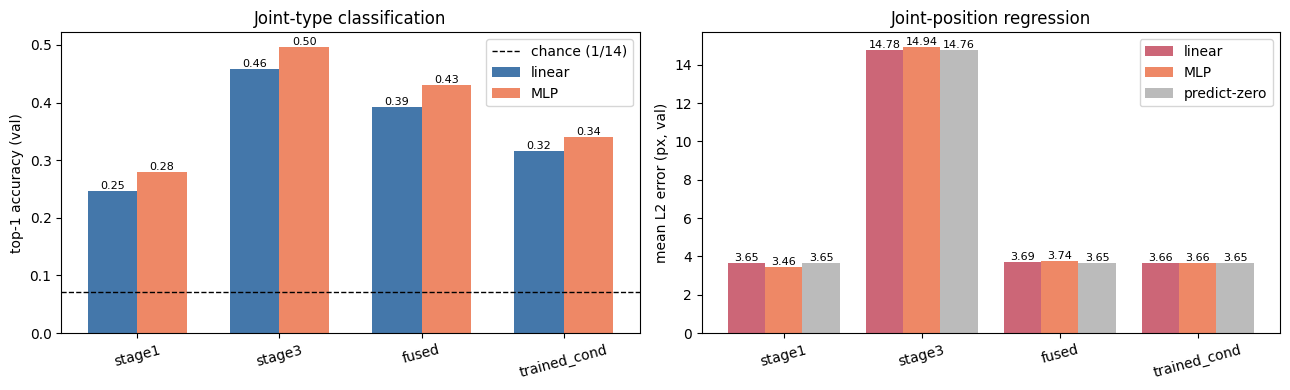

In [28]:
# Full comparison bar chart: stage1 / stage3 / fused / trained_cond, linear + MLP
ALL_FEATS = ["stage1", "stage3", "fused", "trained_cond"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(ALL_FEATS))
w = 0.35

ax = axes[0]
lin_acc = [probe_results[s]["cls"]["acc_val"] for s in ALL_FEATS]
mlp_acc = [mlp_results  [s]["cls"]["acc_val"] for s in ALL_FEATS]
ax.bar(x - w/2, lin_acc, w, color="#4477aa", label="linear")
ax.bar(x + w/2, mlp_acc, w, color="#ee8866", label="MLP")
ax.axhline(1 / 14, color="k", linestyle="--", lw=1, label="chance (1/14)")
ax.set_xticks(x); ax.set_xticklabels(ALL_FEATS, rotation=15)
ax.set_ylabel("top-1 accuracy (val)")
ax.set_title("Joint-type classification")
for xi, (lv, mv) in enumerate(zip(lin_acc, mlp_acc)):
    ax.text(xi - w/2, lv, f"{lv:.2f}", ha="center", va="bottom", fontsize=8)
    ax.text(xi + w/2, mv, f"{mv:.2f}", ha="center", va="bottom", fontsize=8)
ax.legend()

ax = axes[1]
# Use stage1's stride-4 baseline for stage1/fused/trained_cond; stage3 has its own stride-16 baseline.
lin_l2  = [probe_results[s]["reg"]["l2_val_px"]            for s in ALL_FEATS]
mlp_l2  = [mlp_results  [s]["reg"]["l2_val_px"]            for s in ALL_FEATS]
zero_l2 = [probe_results[s]["reg"]["l2_zero_baseline_px"]  for s in ALL_FEATS]
w3 = 0.27
ax.bar(x - w3, lin_l2,  w3, color="#cc6677", label="linear")
ax.bar(x,      mlp_l2,  w3, color="#ee8866", label="MLP")
ax.bar(x + w3, zero_l2, w3, color="#bbbbbb", label="predict-zero")
ax.set_xticks(x); ax.set_xticklabels(ALL_FEATS, rotation=15)
ax.set_ylabel("mean L2 error (px, val)")
ax.set_title("Joint-position regression")
for xi, (lv, mv, zv) in enumerate(zip(lin_l2, mlp_l2, zero_l2)):
    ax.text(xi - w3, lv, f"{lv:.2f}", ha="center", va="bottom", fontsize=8)
    ax.text(xi,      mv, f"{mv:.2f}", ha="center", va="bottom", fontsize=8)
    ax.text(xi + w3, zv, f"{zv:.2f}", ha="center", va="bottom", fontsize=8)
ax.legend()
plt.tight_layout(); plt.show()
